# **MÓDULO 15 - Exercício**
# Análise - A segunda etapa da Pré Modelagem

**Aluno:** Lucas Farias Epitácio de Almeida

Base: clientes de uma empresa de telecomunicações, tratada no Módulo 14. Variável-alvo: **Churn** (cancelamento do serviço).

**Padrões adotados neste notebook**
- Gráficos gerados por **funções parametrizadas e loops**, para evitar repetição de código e manter o mesmo visual em todo o relatório.
- Todas as funções têm **docstring** descrevendo parâmetros e retorno.
- Títulos, eixos, legendas e categorias em **português**, com os mesmos nomes de variáveis em todos os gráficos.
- Tabelas consolidadas (estatísticas, outliers, balanceamento, taxas de churn e importância das variáveis) **salvas em arquivos externos** na pasta `resultados/`.

# 1) O primeiro exercício é o de salvar a base que criaram na atividade do módulo anterior em csv e abrir ela neste arquivo.
Igual fizemos no início do módulo atual no início da primeira aula.

In [1]:
import os
import warnings

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import plotly.express as px

warnings.filterwarnings('ignore')

# Padrão visual único para todos os gráficos
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Pasta onde as tabelas consolidadas serão salvas
PASTA_RESULTADOS = 'resultados'
os.makedirs(PASTA_RESULTADOS, exist_ok=True)

A base usada é a **própria base pré-processada no Módulo 14** (não a base de exemplo da aula). No final do notebook do Módulo 14 ela foi exportada com `df.to_csv('data_preprocessed.csv', index=False)` e agora é aberta aqui.

In [2]:
# Exportação feita no final do Módulo 14:
# df.to_csv('data_preprocessed.csv', index=False)

# Abrindo a base salva (no Colab, enviar o arquivo para a pasta dados/ antes)
df = pd.read_csv('dados/data_preprocessed.csv')

print(df.shape)
df.head()

(2495, 16)


,ID_Cliente,Genero,Idoso,Casado,Dependentes,Tempo_como_Cliente,Servico_Telefone,Servico_Internet,Servico_Seguranca,Suporte_Tecnico,Streaming_TV,Tipo_Contrato,Forma_Pagamento,Pagamento_Mensal,Total_Pago,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,DSL,No,No,No,Month-to-month,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,DSL,Yes,No,No,One year,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,DSL,Yes,No,No,Month-to-month,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,DSL,Yes,Yes,No,One year,Bank transfer (automatic),71.45,1840.75,No
4,9237-HQITU,Male,0,No,No,2,Yes,Fiber optic,No,No,No,Month-to-month,Electronic check,71.45,151.65,Yes


In [3]:
# Tipos das colunas e checagem de valores ausentes
df.info()
print('\nTotal de valores ausentes:', df.isnull().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 2495 entries, 0 to 2494
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID_Cliente          2495 non-null   str    
 1   Genero              2495 non-null   str    
 2   Idoso               2495 non-null   int64  
 3   Casado              2495 non-null   str    
 4   Dependentes         2495 non-null   str    
 5   Tempo_como_Cliente  2495 non-null   int64  
 6   Servico_Telefone    2495 non-null   str    
 7   Servico_Internet    2495 non-null   str    
 8   Servico_Seguranca   2495 non-null   str    
 9   Suporte_Tecnico     2495 non-null   str    
 10  Streaming_TV        2495 non-null   str    
 11  Tipo_Contrato       2495 non-null   str    
 12  Forma_Pagamento     2495 non-null   str    
 13  Pagamento_Mensal    2495 non-null   float64
 14  Total_Pago          2495 non-null   float64
 15  Churn               2495 non-null   str    
dtypes: float64(2), in

A base tem **2.495 clientes e 16 colunas**, sem valores ausentes (o tratamento foi feito no Módulo 14). Há 3 variáveis numéricas contínuas (`Tempo_como_Cliente`, `Pagamento_Mensal`, `Total_Pago`), uma binária numérica (`Idoso`) e as demais categóricas. A coluna `ID_Cliente` é apenas um identificador e não entra na análise.

### Padronização do idioma

As categorias vieram em inglês (`Yes`, `Month-to-month`, `Fiber optic`...), enquanto os nomes das colunas e os títulos estão em português. Para que todos os gráficos e tabelas fiquem no mesmo idioma, as categorias são traduzidas uma única vez aqui, e um dicionário define o nome de exibição de cada variável. `Idoso` continua numérica (0/1) na base, porque é usada em cálculos; só é exibida como Não/Sim nos gráficos.

In [4]:
# Tradução das categorias (aplicada uma vez, vale para todo o notebook)
TRADUCAO = {
    'Genero': {'Male': 'Masculino', 'Female': 'Feminino'},
    'Servico_Internet': {'Fiber optic': 'Fibra óptica', 'DSL': 'DSL', 'No': 'Sem internet'},
    'Tipo_Contrato': {'Month-to-month': 'Mensal', 'One year': '1 ano', 'Two year': '2 anos'},
    'Forma_Pagamento': {'Electronic check': 'Cheque eletrônico',
                        'Mailed check': 'Cheque por correio',
                        'Bank transfer (automatic)': 'Transferência (automática)',
                        'Credit card (automatic)': 'Cartão de crédito (automático)'},
}
SIM_NAO = {'Yes': 'Sim', 'No': 'Não', 'No internet service': 'Sem internet'}

for col in ['Casado', 'Dependentes', 'Servico_Telefone', 'Servico_Seguranca',
            'Suporte_Tecnico', 'Streaming_TV', 'Churn']:
    TRADUCAO[col] = SIM_NAO

for col, mapa in TRADUCAO.items():
    df[col] = df[col].map(mapa)

# Nome de exibição de cada variável nos gráficos (mesmo padrão em todo o relatório)
NOMES = {
    'Genero': 'Gênero', 'Idoso': 'Idoso', 'Casado': 'Casado', 'Dependentes': 'Dependentes',
    'Tempo_como_Cliente': 'Tempo como cliente (meses)', 'Servico_Telefone': 'Serviço de telefone',
    'Servico_Internet': 'Serviço de internet', 'Servico_Seguranca': 'Serviço de segurança',
    'Suporte_Tecnico': 'Suporte técnico', 'Streaming_TV': 'Streaming de TV',
    'Tipo_Contrato': 'Tipo de contrato', 'Forma_Pagamento': 'Forma de pagamento',
    'Pagamento_Mensal': 'Pagamento mensal', 'Total_Pago': 'Total pago', 'Churn': 'Churn',
    'Faixa_Tempo': 'Faixa de tempo como cliente',
}
ROTULOS_IDOSO = {0: 'Não', 1: 'Sim'}

# Conferência: nenhuma categoria ficou sem tradução
print('Valores sem tradução:', df[list(TRADUCAO)].isnull().sum().sum())
df.head()

Valores sem tradução: 0


,ID_Cliente,Genero,Idoso,Casado,Dependentes,Tempo_como_Cliente,Servico_Telefone,Servico_Internet,Servico_Seguranca,Suporte_Tecnico,Streaming_TV,Tipo_Contrato,Forma_Pagamento,Pagamento_Mensal,Total_Pago,Churn
0,7590-VHVEG,Feminino,0,Sim,Não,1,Não,DSL,Não,Não,Não,Mensal,Cheque eletrônico,29.85,29.85,Não
1,5575-GNVDE,Masculino,0,Não,Não,34,Sim,DSL,Sim,Não,Não,1 ano,Cheque por correio,56.95,1889.50,Não
2,3668-QPYBK,Masculino,0,Não,Não,2,Sim,DSL,Sim,Não,Não,Mensal,Cheque por correio,53.85,108.15,Sim
3,7795-CFOCW,Masculino,0,Não,Não,45,Não,DSL,Sim,Sim,Não,1 ano,Transferência (automática),71.45,1840.75,Não
4,9237-HQITU,Masculino,0,Não,Não,2,Sim,Fibra óptica,Não,Não,Não,Mensal,Cheque eletrônico,71.45,151.65,Sim


### Funções de apoio

Todas as visualizações e cálculos repetidos ficam concentrados nas funções abaixo. Assim, cada gráfico do notebook é uma chamada de função ou um loop, e qualquer ajuste de estilo é feito num lugar só.

In [5]:
def rotulos(col, valores):
    """Converte os valores de uma variável em rótulos de exibição.

    Parâmetros
    ----------
    col : str
        Nome da coluna de origem.
    valores : iterável
        Valores (categorias) a converter.

    Retorna
    -------
    list[str]
        Rótulos em português; para 'Idoso', 0/1 viram 'Não'/'Sim'.
    """
    if col == 'Idoso':
        return [ROTULOS_IDOSO.get(v, v) for v in valores]
    return [str(v) for v in valores]


def plot_contagem(col, ax=None, ordem=None, horizontal=False):
    """Gráfico de barras com a contagem e a porcentagem de cada categoria.

    Parâmetros
    ----------
    col : str
        Coluna categórica a ser plotada.
    ax : matplotlib.axes.Axes, opcional
        Eixo onde desenhar; se omitido, usa o eixo atual.
    ordem : list, opcional
        Ordem das categorias; se omitida, da mais para a menos frequente.
    horizontal : bool, padrão False
        Se True, desenha barras horizontais (útil para rótulos longos).

    Retorna
    -------
    matplotlib.axes.Axes
    """
    ax = ax or plt.gca()
    contagem = df[col].value_counts()
    if ordem is not None:
        contagem = contagem.reindex(ordem)
    nomes = rotulos(col, contagem.index)
    total = contagem.sum()

    if horizontal:
        sns.barplot(x=contagem.values, y=nomes, ax=ax)
        for i, v in enumerate(contagem.values):
            ax.text(v + total * 0.005, i, f'{v} ({v / total:.1%})', va='center')
        ax.set_xlabel('Quantidade de clientes')
        ax.set_ylabel(NOMES[col])
        ax.set_xlim(0, contagem.max() * 1.25)
    else:
        sns.barplot(x=nomes, y=contagem.values, ax=ax)
        for i, v in enumerate(contagem.values):
            ax.text(i, v + total * 0.005, f'{v} ({v / total:.1%})', ha='center', va='bottom')
        ax.set_xlabel(NOMES[col])
        ax.set_ylabel('Quantidade de clientes')
        ax.set_ylim(0, contagem.max() * 1.15)
    ax.set_title(f'Distribuição de {NOMES[col].lower()}')
    return ax


def plot_histograma(col, bins=30, ax=None):
    """Histograma com curva de densidade (KDE) de uma variável numérica.

    Parâmetros
    ----------
    col : str
        Coluna numérica a ser plotada.
    bins : int, padrão 30
        Número de faixas do histograma.
    ax : matplotlib.axes.Axes, opcional
        Eixo onde desenhar; se omitido, usa o eixo atual.

    Retorna
    -------
    matplotlib.axes.Axes
    """
    ax = ax or plt.gca()
    sns.histplot(data=df, x=col, bins=bins, kde=True, ax=ax)
    ax.axvline(df[col].median(), color='red', linestyle='--', label=f'Mediana = {df[col].median():.1f}')
    ax.set_title(f'Distribuição de {NOMES[col].lower()}')
    ax.set_xlabel(NOMES[col])
    ax.set_ylabel('Quantidade de clientes')
    ax.legend()
    return ax


def contar_outliers(serie):
    """Conta outliers de uma série numérica pelo critério do IQR (regra de Tukey).

    Parâmetros
    ----------
    serie : pandas.Series
        Valores numéricos a avaliar.

    Retorna
    -------
    tuple (int, float, float)
        Quantidade de outliers, limite inferior e limite superior,
        calculados como Q1 - 1,5*IQR e Q3 + 1,5*IQR.
    """
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((serie < lim_inf) | (serie > lim_sup)).sum(), round(lim_inf, 2), round(lim_sup, 2)


def calcular_taxa_churn(col):
    """Calcula a taxa de churn (%) e o número de clientes de cada categoria.

    Parâmetros
    ----------
    col : str
        Coluna categórica usada para agrupar os clientes.

    Retorna
    -------
    pandas.DataFrame
        Uma linha por categoria, com as colunas 'clientes' e 'taxa_churn_%'.
    """
    churn = (df['Churn'] == 'Sim').astype(int)
    tabela = churn.groupby(df[col], observed=True).agg(['count', 'mean'])
    tabela.columns = ['clientes', 'taxa_churn_%']
    tabela['taxa_churn_%'] = (tabela['taxa_churn_%'] * 100).round(1)
    return tabela


def plot_taxa_churn(col, ax=None, ordem=None):
    """Gráfico de barras da taxa de churn por categoria, com a média geral como referência.

    Parâmetros
    ----------
    col : str
        Coluna categórica a comparar com o churn.
    ax : matplotlib.axes.Axes, opcional
        Eixo onde desenhar; se omitido, usa o eixo atual.
    ordem : list, opcional
        Ordem das categorias (para variáveis com ordem natural, como contrato
        ou faixas de tempo). Se omitida, ordena da maior para a menor taxa.

    Retorna
    -------
    matplotlib.axes.Axes
        Barras acima da linha tracejada indicam grupos com risco acima da média.
    """
    ax = ax or plt.gca()
    taxas = calcular_taxa_churn(col)['taxa_churn_%']
    taxas = taxas.reindex(ordem) if ordem is not None else taxas.sort_values(ascending=False)

    sns.barplot(x=rotulos(col, taxas.index), y=taxas.values, ax=ax)
    for i, v in enumerate(taxas.values):
        ax.text(i, v + 0.8, f'{v:.1f}%', ha='center')
    media = (df['Churn'] == 'Sim').mean() * 100
    ax.axhline(media, color='red', linestyle='--', label=f'Média geral ({media:.1f}%)')
    ax.set_title(f'Taxa de churn por {NOMES[col].lower()}')
    ax.set_xlabel(NOMES[col])
    ax.set_ylabel('Taxa de churn (%)')
    ax.set_ylim(0, max(taxas.max(), media) * 1.15)
    ax.legend()
    return ax

# 2) Comece pela análise univariada:

A) Utilize a função describe no seu dataframe, veja os insights que consegue retirar.

B) Já é possível identificar variáveis com possíveis outliers? Se sim, quais?

C) Plot gráficos que considerar importante para completar sua análise univariada. (Lembrando que sua variável preditora é o churn). Não se esqueça de trazer insights de cada gráfico plotado. Utilize pelo menos 4 variáveis distintas.

D) Verifique se os dados das variáveis Booleanas são balanceados ou não.

## A) describe()

In [6]:
# Estatísticas das variáveis numéricas
desc_num = df.describe().round(2)
desc_num

,Idoso,Tempo_como_Cliente,Pagamento_Mensal,Total_Pago
count,2495.00,2495.00,2495.00,2495.00
mean,0.16,32.35,66.36,2292.63
std,0.37,24.63,28.01,2266.89
min,0.00,0.00,18.40,18.80
25%,0.00,8.00,45.55,402.18
50%,0.00,29.00,71.45,1404.65
75%,0.00,56.00,87.38,3874.75
max,1.00,72.00,118.65,8564.75


In [7]:
# Estatísticas das variáveis categóricas
desc_cat = df.drop(columns='ID_Cliente').describe(include='object').T
desc_cat

,count,unique,top,freq
Genero,2495,2,Masculino,1276
Casado,2495,2,Não,1266
Dependentes,2495,2,Não,1710
Servico_Telefone,2495,2,Sim,2409
Servico_Internet,2495,3,Fibra óptica,1124
Servico_Seguranca,2495,3,Não,1257
Suporte_Tecnico,2495,3,Não,1254
Streaming_TV,2495,3,Não,1003
Tipo_Contrato,2495,3,Mensal,1373
Forma_Pagamento,2495,4,Cheque eletrônico,832


**Insights do describe:**

- **Tempo_como_Cliente** vai de 0 a 72 meses, com média de 32,4 e mediana de 29. A distância entre 1º quartil (8) e 3º quartil (56) é grande: a base mistura muitos clientes novos com muitos clientes antigos.
- **Pagamento_Mensal** varia de 18,40 a 118,65, com mediana (71,45) **maior** que a média (66,36), indicando leve assimetria à esquerda: há um grupo de clientes com planos baratos puxando a média para baixo.
- **Total_Pago** tem média (2.292) bem acima da mediana (1.404) e desvio padrão quase igual à média: distribuição **assimétrica à direita**. Isso é esperado, já que o total pago é praticamente tempo × mensalidade.
- **Idoso** tem média de 0,16, ou seja, só **16% dos clientes são idosos**.
- Nas categóricas: o contrato mais comum é o **mensal** (1.373 clientes, 55%), a forma de pagamento mais comum é o **cheque eletrônico** e o serviço de internet mais comum é a **fibra óptica**.
- **Churn = "Não"** aparece em 1.846 de 2.495 registros, então cerca de **26% dos clientes cancelaram**.

## B) Identificação de possíveis outliers

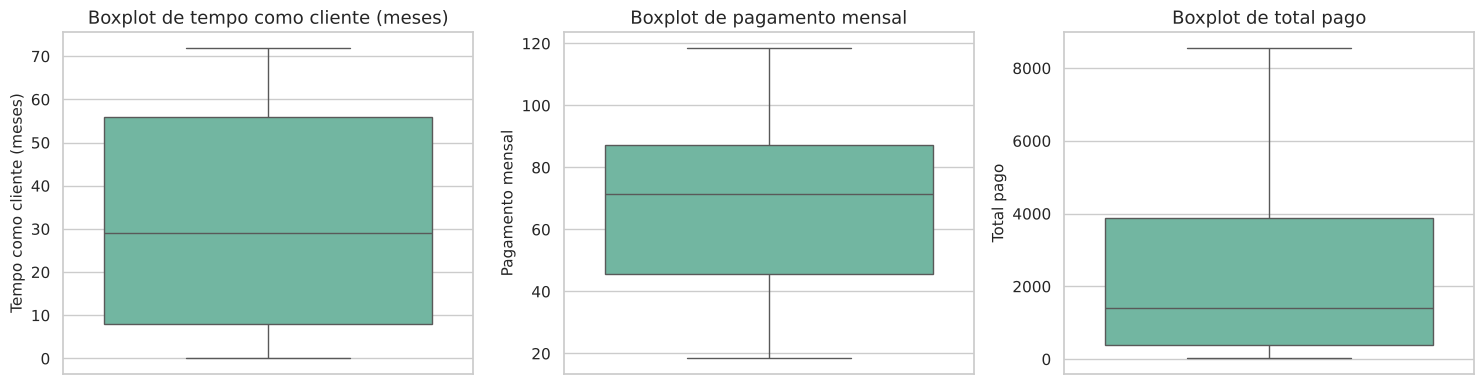

In [8]:
# Boxplots das variáveis numéricas contínuas, gerados em loop
num_cols = ['Tempo_como_Cliente', 'Pagamento_Mensal', 'Total_Pago']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f'Boxplot de {NOMES[col].lower()}')
    ax.set_ylabel(NOMES[col])
plt.tight_layout()
plt.show()

In [9]:
# Contagem de outliers pelo critério do IQR
resumo_outliers = pd.DataFrame(
    [contar_outliers(df[c]) for c in num_cols],
    index=num_cols, columns=['qtd_outliers', 'limite_inferior', 'limite_superior']
)
resumo_outliers['minimo'] = df[num_cols].min().values
resumo_outliers['maximo'] = df[num_cols].max().values
resumo_outliers['assimetria'] = df[num_cols].skew().round(2).values
resumo_outliers

,qtd_outliers,limite_inferior,limite_superior,minimo,maximo,assimetria
Tempo_como_Cliente,0,-64.00,128.00,0.0,72.00,0.24
Pagamento_Mensal,0,-17.19,150.11,18.4,118.65,-0.38
Total_Pago,0,-4806.69,9083.61,18.8,8564.75,0.94


**Resposta:** pelo describe, a variável que mais **levanta suspeita** é `Total_Pago`, por causa da diferença grande entre média e mediana e do máximo (8.564,75) distante do 3º quartil (3.874,75). Porém, ao aplicar o critério do IQR, **nenhuma das três variáveis numéricas tem outliers**: todos os valores estão dentro dos limites. A cauda longa de `Total_Pago` é assimetria natural (clientes antigos acumulam mais pagamentos), e não valores anômalos. O tratamento formal é feito na questão 3.

## C) Gráficos da análise univariada

### Gráfico 1 – Churn (variável-alvo)

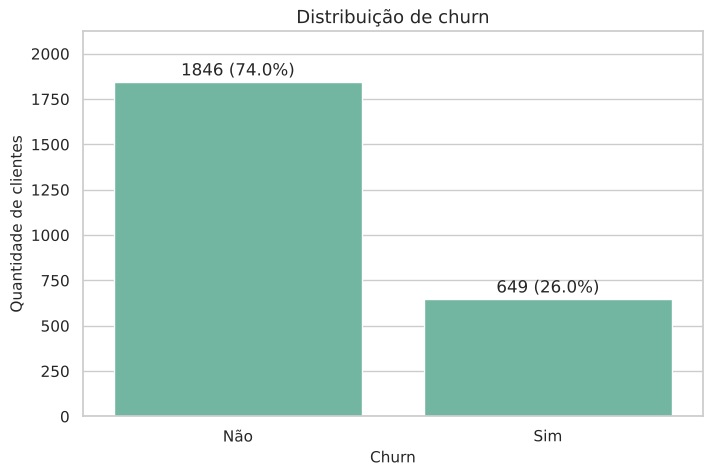

In [10]:
plot_contagem('Churn', ordem=['Não', 'Sim'])
plt.show()

**Insight:** 1.846 clientes (74%) permaneceram e 649 (26%) cancelaram. A variável-alvo é **desbalanceada** na proporção de quase 3 para 1. Isso precisa ser considerado na modelagem: um modelo que sempre previsse "Não" já acertaria 74%, então a acurácia sozinha não é uma boa métrica. Vale olhar recall/precisão da classe "Sim" e considerar técnicas como estratificação ou balanceamento.

### Gráficos 2 a 4 – Variáveis numéricas

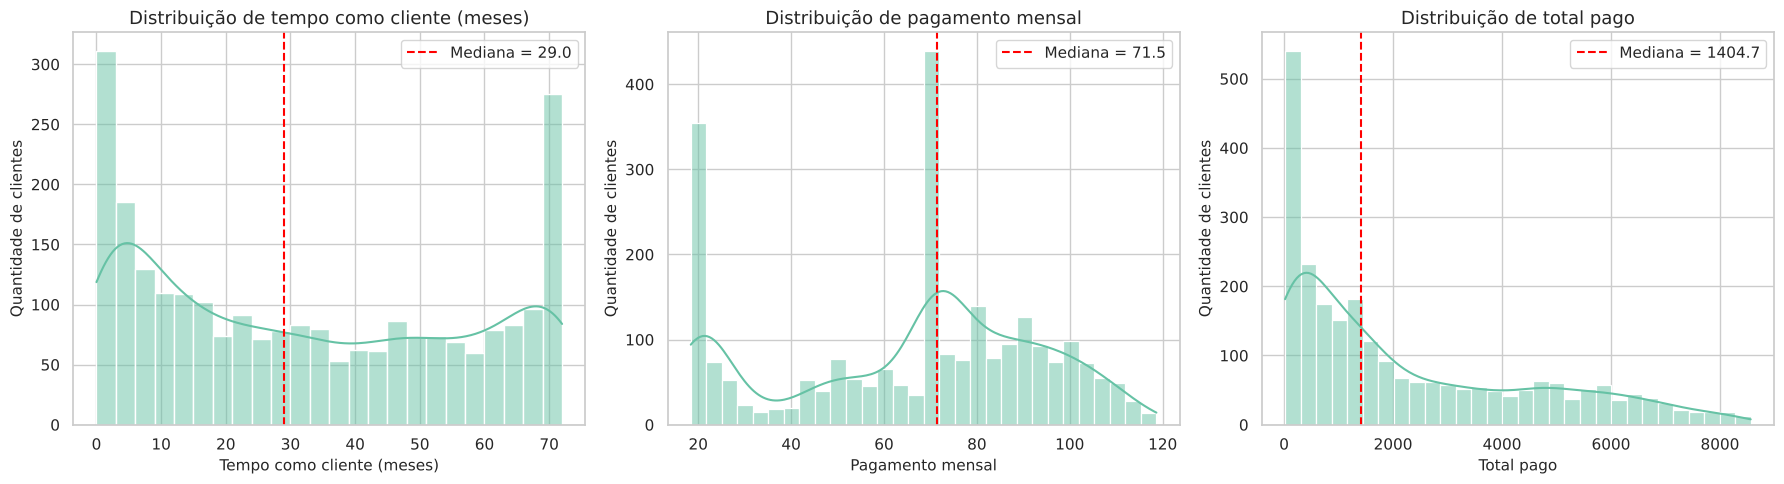

In [11]:
# Um histograma por variável numérica, gerados em loop com a mesma função
bins_por_variavel = {'Tempo_como_Cliente': 24, 'Pagamento_Mensal': 30, 'Total_Pago': 30}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (col, bins) in zip(axes, bins_por_variavel.items()):
    plot_histograma(col, bins=bins, ax=ax)
plt.tight_layout()
plt.show()

**Insight – Tempo como cliente:** a distribuição tem formato de **"U"**: um pico nos primeiros meses (clientes recém-chegados) e outro perto de 72 meses (clientes fiéis de longa data). O meio da distribuição é mais baixo. São dois perfis bem distintos, e o grupo dos primeiros meses é candidato natural a concentrar os cancelamentos (verificado na bivariada).

**Insight – Pagamento mensal:** há um **pico grande entre 18 e 25**, que corresponde aos planos mais básicos (geralmente só telefone, sem internet), e uma concentração maior entre 70 e 105, que são os planos com internet e serviços adicionais. A distribuição não é normal, por isso a mediana (71,45) representa melhor o cliente típico do que a média.

**Insight – Total pago:** forte **assimetria à direita** (skew ≈ 0,94): a maioria dos clientes pagou pouco no total e poucos chegaram a valores altos. Faz sentido, pois o total pago depende diretamente do tempo como cliente. Essa dependência indica que `Total_Pago` pode ser redundante com `Tempo_como_Cliente` (tratado após a matriz de correlação).

### Gráficos 5 a 7 – Variáveis categóricas de serviço e contrato

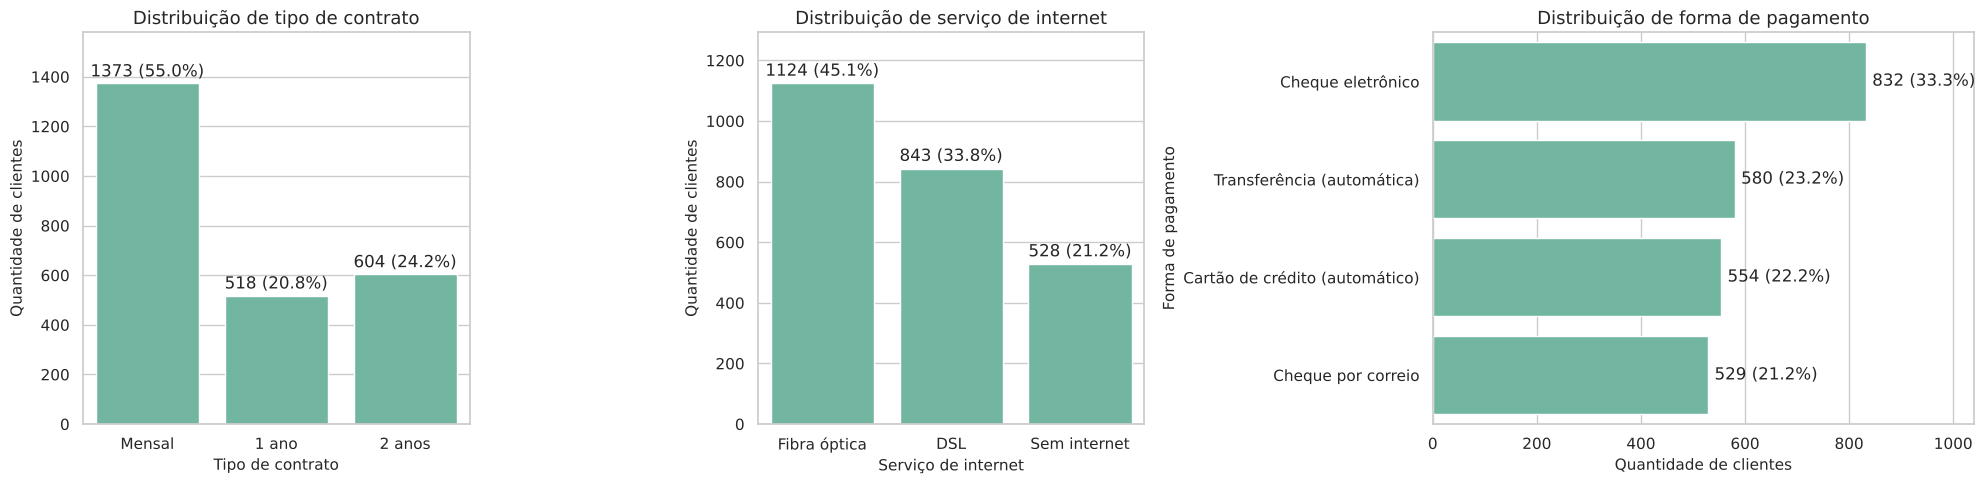

In [12]:
# Configuração de cada gráfico categórico: (coluna, ordem, barras horizontais?)
graficos_categoricos = [
    ('Tipo_Contrato', ['Mensal', '1 ano', '2 anos'], False),
    ('Servico_Internet', None, False),
    ('Forma_Pagamento', None, True),
]

fig, axes = plt.subplots(1, 3, figsize=(20, 5), gridspec_kw={'width_ratios': [1, 1, 1.4]})
for ax, (col, ordem, horizontal) in zip(axes, graficos_categoricos):
    plot_contagem(col, ax=ax, ordem=ordem, horizontal=horizontal)
plt.tight_layout()
plt.show()

**Insight – Tipo de contrato:** **55% dos clientes têm contrato mensal**, que não gera multa nem compromisso de permanência. Os contratos de 1 e 2 anos somam 45%. Como o contrato mensal facilita a saída, é uma variável com grande potencial de explicar o churn.

**Insight – Serviço de internet:** a **fibra óptica** é o serviço mais contratado (1.124 clientes, 45%), seguida do DSL (34%); 21% não têm internet. As colunas `Servico_Seguranca`, `Suporte_Tecnico` e `Streaming_TV` têm exatamente 528 registros "Sem internet", o mesmo número de clientes sem internet, o que confirma a consistência da base.

**Insight – Forma de pagamento:** o **cheque eletrônico** lidera (33%), e as outras três formas estão equilibradas entre si (21–23% cada). As barras horizontais foram usadas porque os nomes das formas de pagamento são longos.

## D) Balanceamento das variáveis booleanas

In [13]:
# Variáveis com apenas duas categorias
booleanas = ['Genero', 'Idoso', 'Casado', 'Dependentes', 'Servico_Telefone', 'Churn']
LIMITE_BALANCEAMENTO = 0.60   # classe majoritária com até 60% = balanceada

linhas = []
for col in booleanas:
    prop = df[col].value_counts(normalize=True)
    nomes = rotulos(col, prop.index)
    linhas.append({'variavel': col,
                   'classe_majoritaria': nomes[0], 'proporcao_majoritaria': round(prop.iloc[0], 3),
                   'classe_minoritaria': nomes[1], 'proporcao_minoritaria': round(prop.iloc[1], 3)})

balanco = pd.DataFrame(linhas).set_index('variavel')
balanco['situacao'] = np.where(balanco['proporcao_majoritaria'] <= LIMITE_BALANCEAMENTO,
                               'Balanceada', 'Desbalanceada')
balanco

,classe_majoritaria,proporcao_majoritaria,classe_minoritaria,proporcao_minoritaria,situacao
variavel,,,,,
Genero,Masculino,0.511,Feminino,0.489,Balanceada
Idoso,Não,0.839,Sim,0.161,Desbalanceada
Casado,Não,0.507,Sim,0.493,Balanceada
Dependentes,Não,0.685,Sim,0.315,Desbalanceada
Servico_Telefone,Sim,0.966,Não,0.034,Desbalanceada
Churn,Não,0.740,Sim,0.260,Desbalanceada


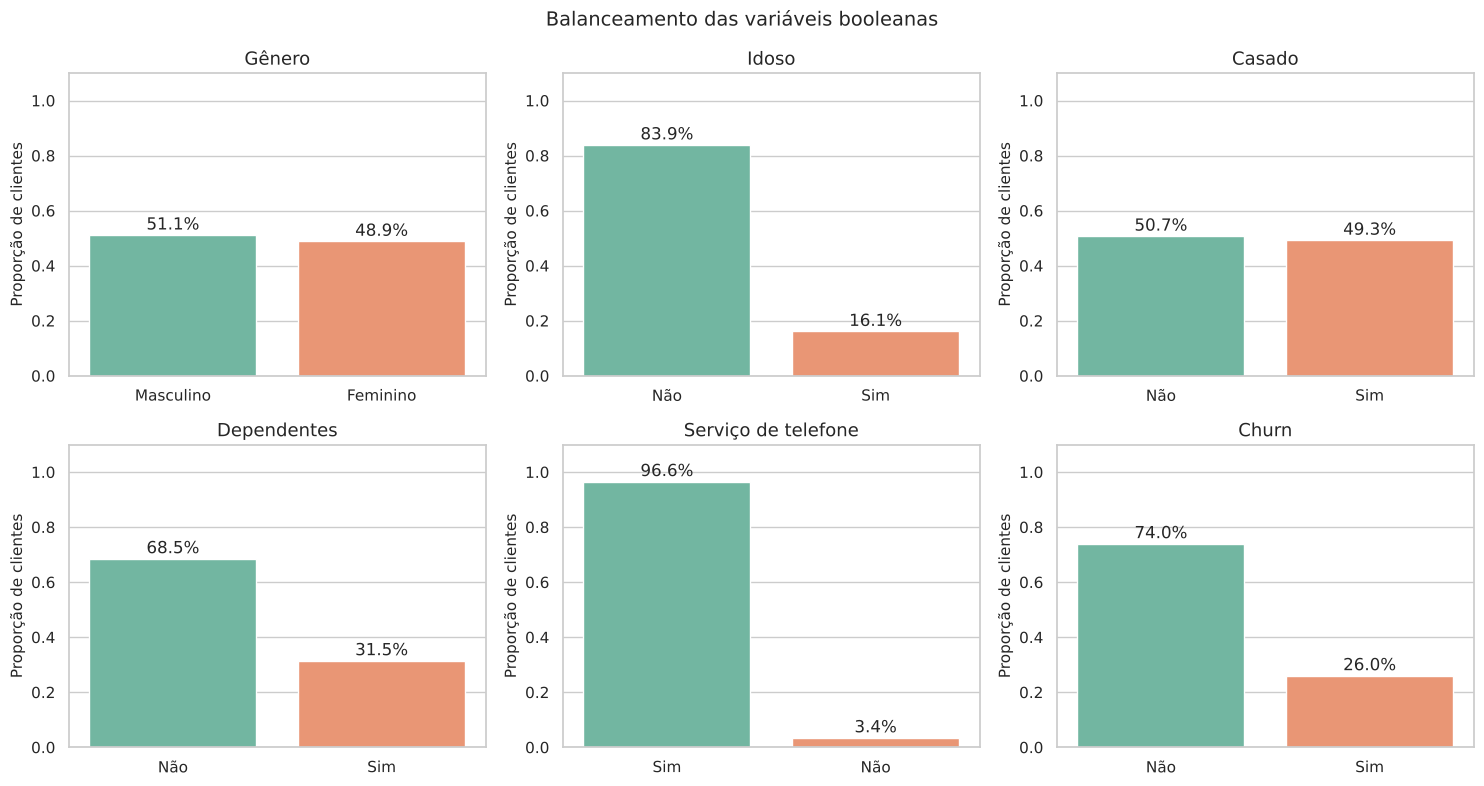

In [14]:
# Gráficos de barras do balanceamento, gerados em loop com escala fixa (0 a 1)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, booleanas):
    prop = df[col].value_counts(normalize=True)
    sns.barplot(x=rotulos(col, prop.index), y=prop.values, ax=ax, palette=['#66c2a5', '#fc8d62'])
    for i, v in enumerate(prop.values):
        ax.text(i, v + 0.02, f'{v:.1%}', ha='center')
    ax.set_title(NOMES[col])
    ax.set_xlabel('')
    ax.set_ylabel('Proporção de clientes')
    ax.set_ylim(0, 1.1)
plt.suptitle('Balanceamento das variáveis booleanas', fontsize=14)
plt.tight_layout()
plt.show()

**Resposta:**

- **Balanceadas:** `Genero` (51% masculino / 49% feminino) e `Casado` (51% / 49%).
- **Desbalanceadas:** `Dependentes` (69% sem dependentes), `Churn` (74% / 26%), `Idoso` (84% não idosos) e, de forma extrema, `Servico_Telefone` (97% têm telefone).

**Impacto do resultado:**

- **Churn (alvo):** é o desbalanceamento mais importante. Na modelagem, a divisão treino/teste deve ser **estratificada** (manter os 26% de churn nos dois conjuntos), e a avaliação deve usar recall, precisão e F1 da classe "Sim", não só a acurácia. Se o modelo tiver dificuldade em identificar quem cancela, dá para testar balanceamento (pesos de classe, undersampling ou SMOTE).
- **Servico_Telefone:** com 97% numa só categoria, a variável quase não varia e tende a contribuir muito pouco para o modelo; é candidata a ser descartada.
- **Idoso e Dependentes:** o desbalanceamento não é problema por si só, já que são preditoras, mas as conclusões sobre os grupos minoritários (402 idosos, 785 com dependentes) se apoiam em menos registros, então devem ser interpretadas com mais cautela.
- **Genero e Casado:** balanceadas, sem necessidade de cuidado especial.

# 3) Identifique e trate as colunas que contém outliers.
Caso opte por mante-los ou altera-los justifique sua escolha.

In [15]:
# Limites do IQR comparados com os valores mínimo e máximo de cada variável
for col in num_cols:
    qtd, li, ls = contar_outliers(df[col])
    print(f'{NOMES[col]}: {qtd} outliers | limites [{li}, {ls}] | mín. = {df[col].min()} | máx. = {df[col].max()}')

Tempo como cliente (meses): 0 outliers | limites [-64.0, 128.0] | mín. = 0 | máx. = 72
Pagamento mensal: 0 outliers | limites [-17.19, 150.11] | mín. = 18.4 | máx. = 118.65
Total pago: 0 outliers | limites [-4806.69, 9083.61] | mín. = 18.8 | máx. = 8564.75


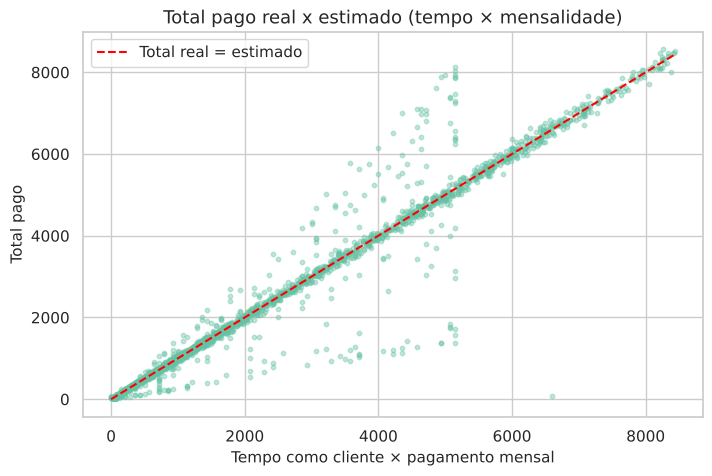

,Tempo_como_Cliente,Pagamento_Mensal,Total_Pago,Churn
483,0,52.55,52.55,Não
748,0,20.25,40.50,Não
931,0,80.85,80.85,Não
1077,0,25.75,25.75,Não
1335,0,56.05,56.05,Não


In [16]:
# Checagem de consistência: Total_Pago deve ser aproximadamente Tempo x Pagamento_Mensal
estimado = df['Tempo_como_Cliente'] * df['Pagamento_Mensal']
plt.scatter(estimado, df['Total_Pago'], alpha=0.4, s=10)
plt.plot([0, estimado.max()], [0, estimado.max()], color='red', linestyle='--', label='Total real = estimado')
plt.title('Total pago real x estimado (tempo × mensalidade)')
plt.xlabel('Tempo como cliente × pagamento mensal')
plt.ylabel(NOMES['Total_Pago'])
plt.legend()
plt.show()

# Clientes com 0 meses (entraram no período da coleta)
df[df['Tempo_como_Cliente'] == 0][['Tempo_como_Cliente', 'Pagamento_Mensal', 'Total_Pago', 'Churn']]

**Decisão: manter os dados sem alteração.**

Justificativa:

1. **Nenhuma variável numérica apresenta outliers** pelo critério do IQR. Todos os valores estão dentro de faixas plausíveis: tempo de 0 a 72 meses (6 anos) e mensalidades de 18,40 a 118,65.
2. A cauda longa de `Total_Pago` é **assimetria natural**, não erro. O gráfico acima mostra que os pontos seguem a reta tempo × mensalidade, ou seja, os valores altos pertencem a clientes antigos com planos caros, que são justamente os clientes mais valiosos para a empresa. Removê-los distorceria a análise.
3. Os 5 clientes com `Tempo_como_Cliente = 0` são clientes novos e têm `Total_Pago` coerente (próximo de uma mensalidade). Também são mantidos.
4. Caso o modelo escolhido seja sensível à escala ou à assimetria (ex.: regressão logística), a alternativa adequada é **transformar** a variável (log ou padronização) na etapa de modelagem, e não excluir registros.

# 4) Realize a etapa da análise bivariada:
A) Questione pelo menos 5 informações e traga as respostas utilizando visuais gráficos e insights.

B) Quais variáveis você acredita serem as mais importantes para esse projetos relacionadas a variável Churn?

As perguntas usam as funções `calcular_taxa_churn` e `plot_taxa_churn`, definidas no início do notebook. A linha tracejada vermelha em cada gráfico é a taxa geral de churn (26%): barras acima dela indicam grupos de risco.

### Pergunta 1: O tipo de contrato influencia o cancelamento?

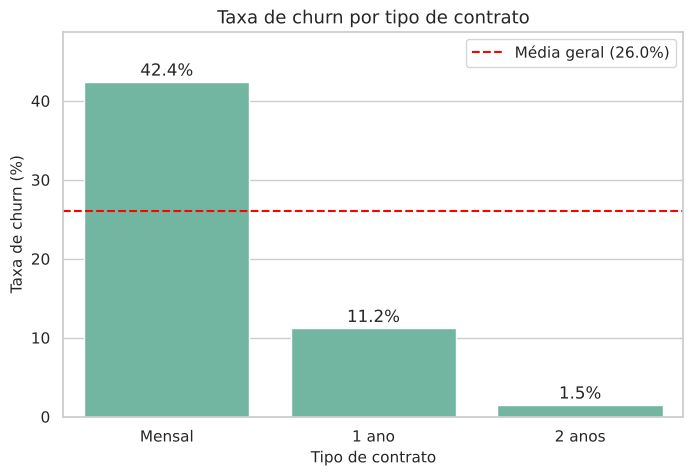

In [17]:
plot_taxa_churn('Tipo_Contrato', ordem=['Mensal', '1 ano', '2 anos'])
plt.show()

**Insight:** sim, e de forma muito forte. O contrato **mensal tem 42,4% de churn**, contra 11,2% no anual e apenas **1,5% no de 2 anos**. Quase metade dos clientes sem fidelidade cancela. Oferecer vantagens para migrar clientes do plano mensal para contratos mais longos é uma das ações de retenção mais promissoras.

### Pergunta 2: Clientes novos cancelam mais que clientes antigos?

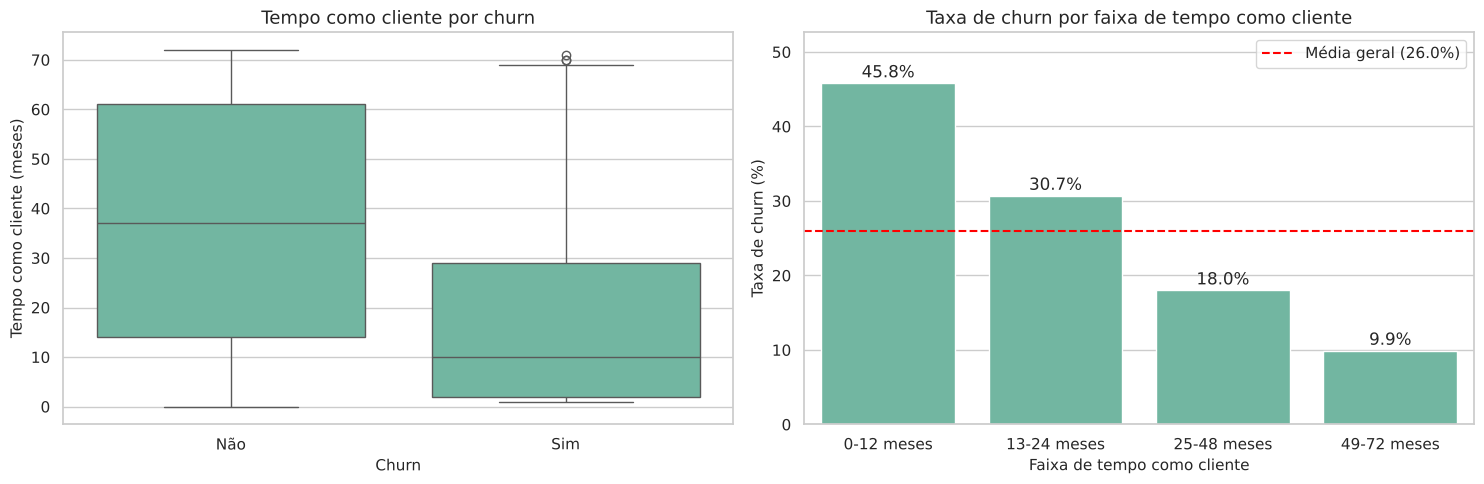

Churn
Não    37.0
Sim    10.0
Name: Mediana do tempo (meses), dtype: float64

In [18]:
# Faixas de tempo como cliente (o corte inicial -1 inclui os clientes com 0 meses)
FAIXAS_TEMPO = ['0-12 meses', '13-24 meses', '25-48 meses', '49-72 meses']
df['Faixa_Tempo'] = pd.cut(df['Tempo_como_Cliente'], bins=[-1, 12, 24, 48, 72], labels=FAIXAS_TEMPO)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x='Churn', y='Tempo_como_Cliente', order=['Não', 'Sim'], ax=axes[0])
axes[0].set_title('Tempo como cliente por churn')
axes[0].set_xlabel('Churn')
axes[0].set_ylabel(NOMES['Tempo_como_Cliente'])

plot_taxa_churn('Faixa_Tempo', ax=axes[1], ordem=FAIXAS_TEMPO)
plt.tight_layout()
plt.show()

df.groupby('Churn')['Tempo_como_Cliente'].median().rename('Mediana do tempo (meses)')

**Insight:** sim. A mediana de tempo de quem **cancelou é 10 meses**, contra **37 meses** de quem ficou. No primeiro ano, a taxa de churn é de **45,8%**, e ela cai de forma consistente com o tempo, até 9,9% entre clientes com mais de 4 anos. O primeiro ano é o período crítico: ações de acompanhamento e onboarding devem se concentrar nele.

### Pergunta 3: Quem paga mensalidades mais altas cancela mais?

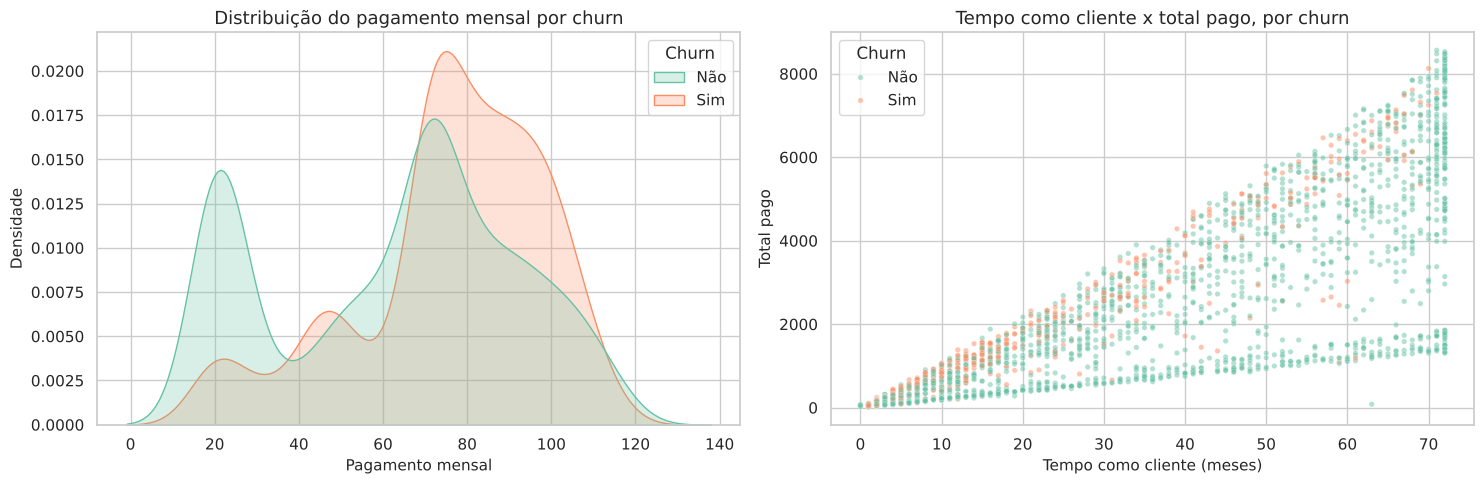

,Pagamento_Mensal,Total_Pago
Churn,,
Não,71.45,1652.675
Sim,79.00,734.350


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.kdeplot(data=df, x='Pagamento_Mensal', hue='Churn', hue_order=['Não', 'Sim'],
            fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('Distribuição do pagamento mensal por churn')
axes[0].set_xlabel(NOMES['Pagamento_Mensal'])
axes[0].set_ylabel('Densidade')

sns.scatterplot(data=df, x='Tempo_como_Cliente', y='Total_Pago', hue='Churn', hue_order=['Não', 'Sim'],
                alpha=0.5, s=15, ax=axes[1])
axes[1].set_title('Tempo como cliente x total pago, por churn')
axes[1].set_xlabel(NOMES['Tempo_como_Cliente'])
axes[1].set_ylabel(NOMES['Total_Pago'])

plt.tight_layout()
plt.show()

df.groupby('Churn')[['Pagamento_Mensal', 'Total_Pago']].median()

**Insight:** sim. Entre os clientes que cancelaram, a densidade se concentra na faixa de **70 a 105** de mensalidade (mediana de 79,00, contra 71,45 de quem ficou). Já entre os que permaneceram há um pico grande nos planos baratos (~20). O gráfico de dispersão mostra que os cancelamentos se concentram no canto inferior esquerdo, ou seja, **pouco tempo de casa**, e por isso o `Total_Pago` de quem cancelou é menor (mediana de 734 contra 1.653). O perfil de risco é: cliente recente pagando caro.

### Perguntas 4 e 5: O tipo de internet e a forma de pagamento estão associados ao cancelamento?

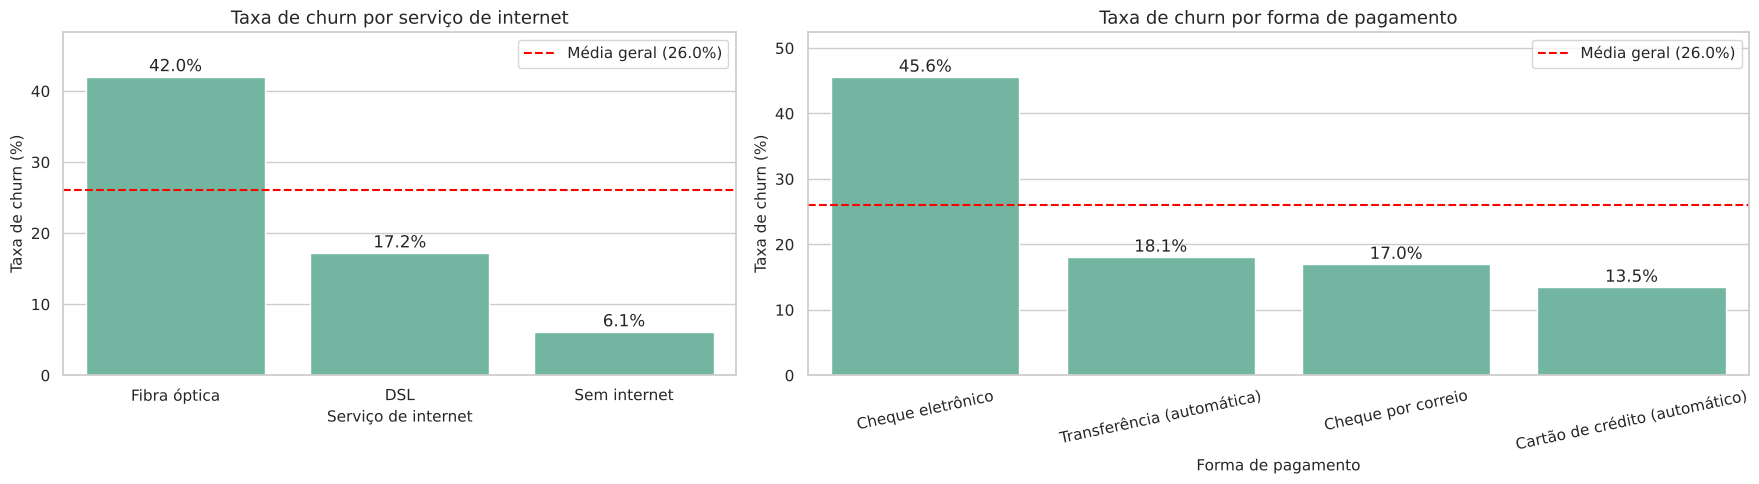

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [1, 1.4]})
plot_taxa_churn('Servico_Internet', ax=axes[0], ordem=['Fibra óptica', 'DSL', 'Sem internet'])
plot_taxa_churn('Forma_Pagamento', ax=axes[1])
axes[1].tick_params(axis='x', rotation=12)
plt.tight_layout()
plt.show()

**Insight – Internet:** clientes com **fibra óptica cancelam 42,0%**, mais que o dobro do DSL (17,2%), e quem não tem internet cancela só 6,1%. Como a fibra é o serviço mais caro, isso se conecta com a pergunta anterior. Vale a empresa investigar se há problema de qualidade, preço ou concorrência no serviço de fibra, já que ele é o mais vendido.

**Insight – Pagamento:** o **cheque eletrônico tem 45,6% de churn**, muito acima das demais formas (13,5% a 18,1%). As formas **automáticas** (cartão e transferência) estão entre as menores taxas: quando o pagamento é automático, o cliente precisa tomar uma decisão ativa para sair. Incentivar o débito automático pode ajudar na retenção.

### Pergunta 6: Serviços de suporte técnico e segurança reduzem o churn?

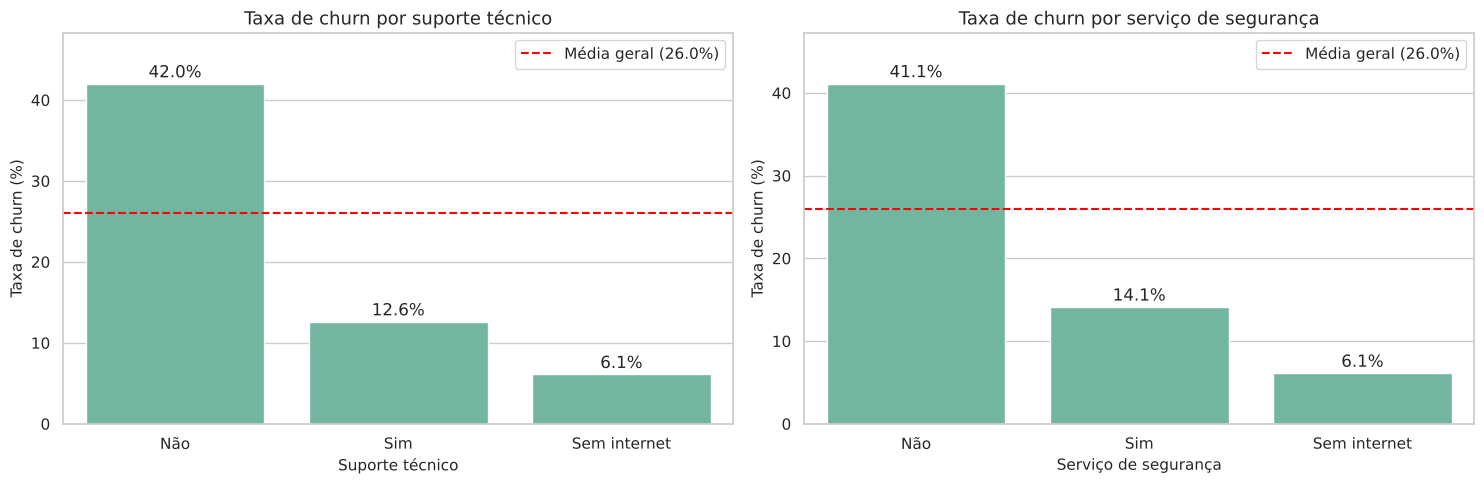

In [21]:
ORDEM_SERVICO = ['Não', 'Sim', 'Sem internet']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, col in zip(axes, ['Suporte_Tecnico', 'Servico_Seguranca']):
    plot_taxa_churn(col, ax=ax, ordem=ORDEM_SERVICO)
plt.tight_layout()
plt.show()

**Insight:** sim. Entre clientes com internet, quem **não tem suporte técnico cancela 42,0%**, contra 12,6% de quem tem. O padrão se repete em segurança (41,1% x 14,1%). Esses serviços parecem aumentar o vínculo do cliente com a empresa. Oferecer suporte técnico gratuito por um período para clientes de risco é uma estratégia possível.

### Pergunta 7: O perfil do cliente (idoso, dependentes, casado, gênero) muda o churn?

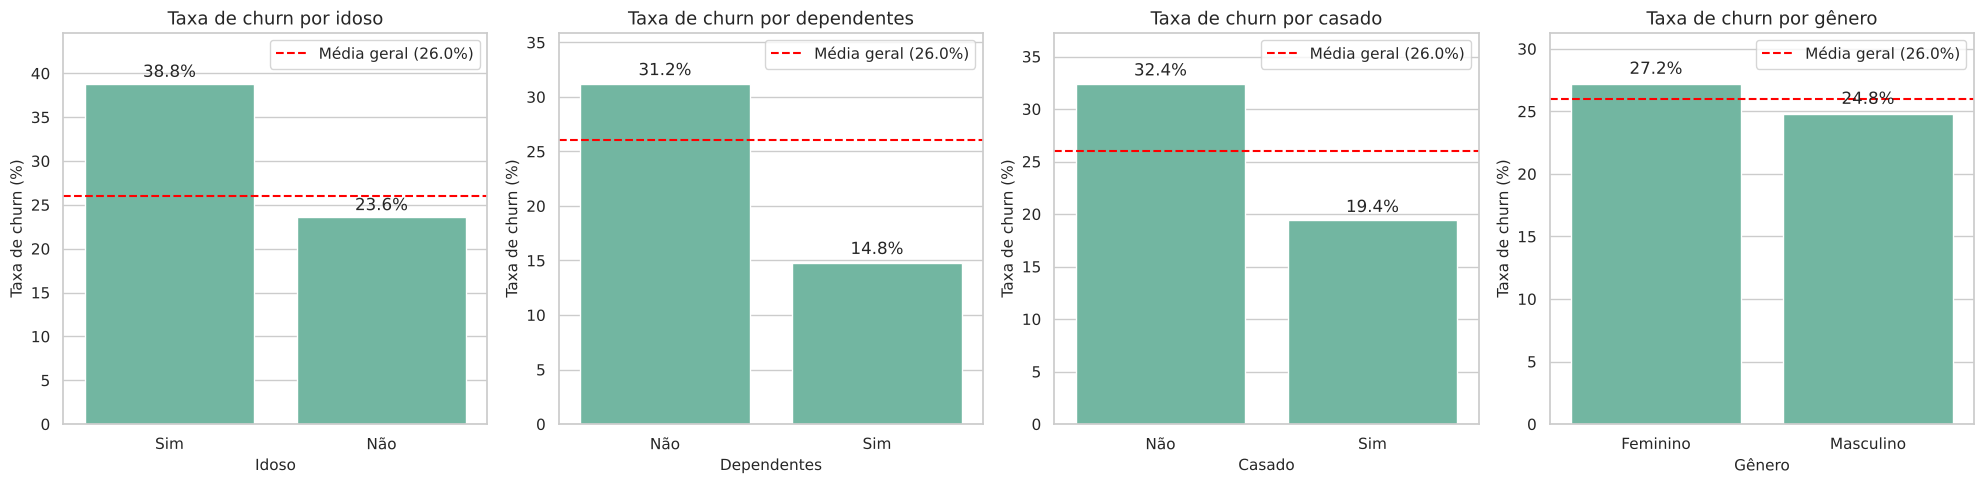

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, col in zip(axes, ['Idoso', 'Dependentes', 'Casado', 'Genero']):
    plot_taxa_churn(col, ax=ax)
plt.tight_layout()
plt.show()

**Insight:** **idosos cancelam mais** (38,8% x 23,6%). Ter **dependentes** (14,8% x 31,2%) ou ser **casado** (19,4% x 32,4%) reduz o churn, possivelmente porque planos familiares são mais difíceis de trocar. Já o **gênero praticamente não faz diferença** (27,2% x 24,8%), então tende a ser uma variável pouco útil para o modelo.

### Pergunta 8: Como as variáveis numéricas se correlacionam entre si e com o churn?

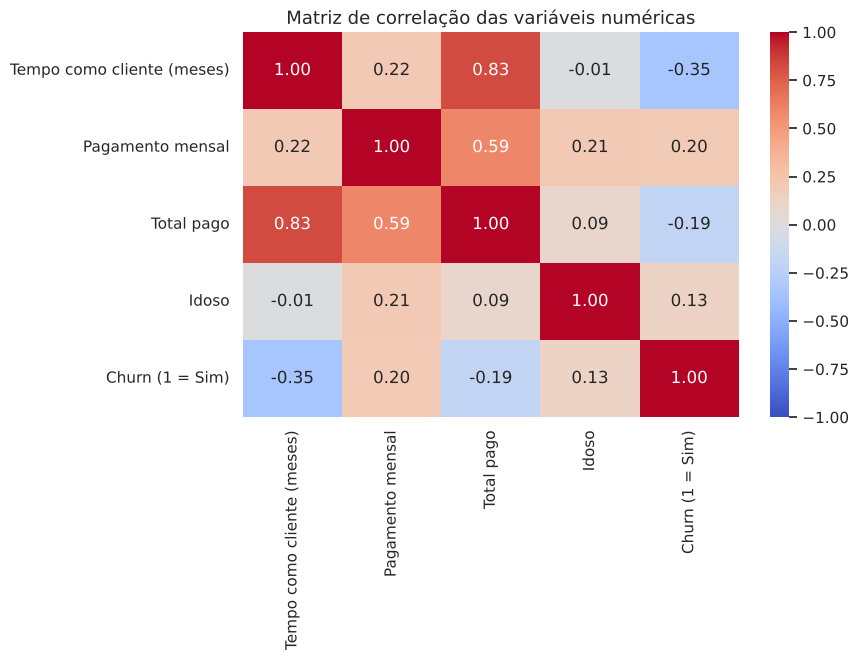

In [23]:
df['Churn_num'] = (df['Churn'] == 'Sim').astype(int)
cols_corr = ['Tempo_como_Cliente', 'Pagamento_Mensal', 'Total_Pago', 'Idoso', 'Churn_num']
nomes_corr = [NOMES.get(c, 'Churn (1 = Sim)') for c in cols_corr]

corr = df[cols_corr].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            xticklabels=nomes_corr, yticklabels=nomes_corr)
plt.title('Matriz de correlação das variáveis numéricas')
plt.show()

**Insight:** com o churn, a maior correlação é com o **tempo como cliente (-0,35)**: quanto mais tempo, menor a chance de cancelar. O pagamento mensal tem correlação positiva (0,20). Entre as preditoras, `Tempo_como_Cliente` e `Total_Pago` têm **correlação de 0,83**, ou seja, carregam quase a mesma informação.

### Tratamento das variáveis fortemente correlacionadas

Antes da modelagem, pares de preditoras com correlação acima de 0,7 (em módulo) são identificados automaticamente, e uma variável de cada par é retirada da base de modelagem. Manter as duas causaria **multicolinearidade**: em modelos como a regressão logística, os coeficientes ficam instáveis e difíceis de interpretar.

In [24]:
LIMITE_CORRELACAO = 0.70
preditoras = ['Tempo_como_Cliente', 'Pagamento_Mensal', 'Total_Pago', 'Idoso']
matriz = df[preditoras].corr().abs()

# Percorre só a metade de cima da matriz para não repetir pares
pares = [(a, b, round(matriz.loc[a, b], 2))
         for i, a in enumerate(preditoras) for b in preditoras[i + 1:]
         if matriz.loc[a, b] > LIMITE_CORRELACAO]
pares_correlacionados = pd.DataFrame(pares, columns=['variavel_1', 'variavel_2', 'correlacao'])
print(pares_correlacionados)

# Correlação de cada uma com o churn, para decidir qual manter
df[['Tempo_como_Cliente', 'Total_Pago']].corrwith(df['Churn_num']).round(2).rename('correlacao_com_churn')

           variavel_1  variavel_2  correlacao
0  Tempo_como_Cliente  Total_Pago        0.83


Tempo_como_Cliente   -0.35
Total_Pago           -0.19
Name: correlacao_com_churn, dtype: float64

In [25]:
# Base de modelagem: sem o identificador e sem a variável redundante
df_modelagem = df.drop(columns=['ID_Cliente', 'Total_Pago', 'Churn_num', 'Faixa_Tempo'])
df_modelagem.to_csv('dados/data_modelagem.csv', index=False)
print(df_modelagem.shape)
df_modelagem.head()

(2495, 14)


,Genero,Idoso,Casado,Dependentes,Tempo_como_Cliente,Servico_Telefone,Servico_Internet,Servico_Seguranca,Suporte_Tecnico,Streaming_TV,Tipo_Contrato,Forma_Pagamento,Pagamento_Mensal,Churn
0,Feminino,0,Sim,Não,1,Não,DSL,Não,Não,Não,Mensal,Cheque eletrônico,29.85,Não
1,Masculino,0,Não,Não,34,Sim,DSL,Sim,Não,Não,1 ano,Cheque por correio,56.95,Não
2,Masculino,0,Não,Não,2,Sim,DSL,Sim,Não,Não,Mensal,Cheque por correio,53.85,Sim
3,Masculino,0,Não,Não,45,Não,DSL,Sim,Sim,Não,1 ano,Transferência (automática),71.45,Não
4,Masculino,0,Não,Não,2,Sim,Fibra óptica,Não,Não,Não,Mensal,Cheque eletrônico,71.45,Sim


**Decisão:** o único par acima do limite é `Tempo_como_Cliente` × `Total_Pago` (0,83). Foi mantido **`Tempo_como_Cliente`**, porque:

1. tem correlação mais forte com o churn (-0,35 contra -0,19);
2. é mais fácil de interpretar e de transformar em ação ("atenção ao primeiro ano");
3. `Total_Pago` é, na prática, tempo × mensalidade; com `Tempo_como_Cliente` e `Pagamento_Mensal` no modelo, a informação dele já está representada.

A base original (`df`) continua completa para a análise; a base reduzida foi salva como `dados/data_modelagem.csv` para a próxima etapa.

## B) Variáveis mais importantes para o Churn

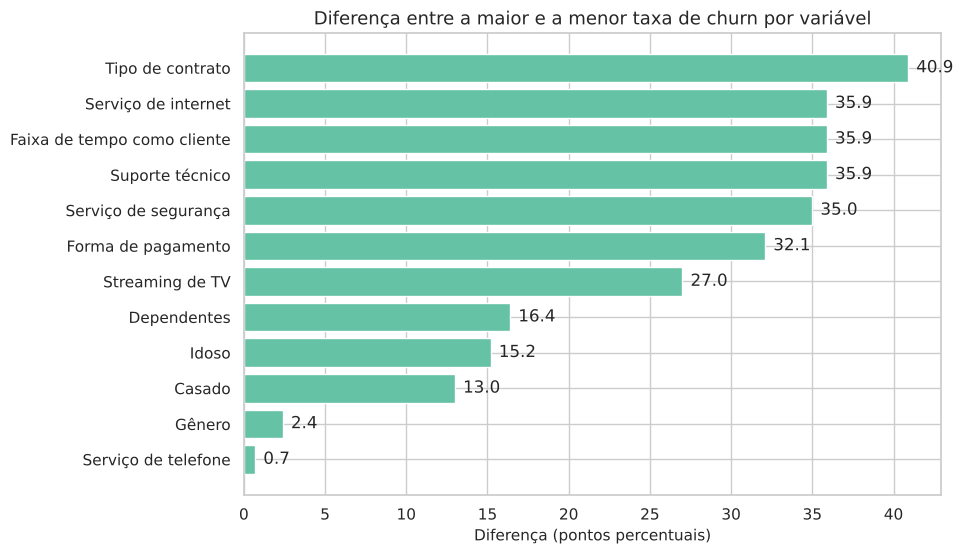

In [26]:
# Taxa de churn de todas as variáveis categóricas, calculada em loop
cat_cols = ['Tipo_Contrato', 'Forma_Pagamento', 'Servico_Internet', 'Suporte_Tecnico',
            'Servico_Seguranca', 'Faixa_Tempo', 'Dependentes', 'Casado', 'Idoso',
            'Streaming_TV', 'Genero', 'Servico_Telefone']

taxas_por_variavel = pd.concat(
    {col: calcular_taxa_churn(col) for col in cat_cols}, names=['variavel', 'categoria']
)

# Amplitude: diferença entre a maior e a menor taxa de churn dentro de cada variável
importancia = (taxas_por_variavel.groupby(level='variavel')['taxa_churn_%']
               .agg(lambda t: t.max() - t.min()).round(1)
               .rename('amplitude_pp').sort_values(ascending=False).to_frame())
importancia['variavel_exibicao'] = [NOMES[c] for c in importancia.index]

plot_dados = importancia.sort_values('amplitude_pp')
plt.figure(figsize=(9, 6))
plt.barh(plot_dados['variavel_exibicao'], plot_dados['amplitude_pp'], color='#66c2a5')
for i, v in enumerate(plot_dados['amplitude_pp']):
    plt.text(v + 0.5, i, f'{v:.1f}', va='center')
plt.title('Diferença entre a maior e a menor taxa de churn por variável')
plt.xlabel('Diferença (pontos percentuais)')
plt.ylabel('')
plt.show()

**Observação sobre `Streaming_TV`:** a amplitude dela (27 pontos) é enganosa. A diferença vem do grupo "Sem internet" (6,1%); entre quem tem e quem não tem streaming, a diferença é de apenas 3,5 pontos.

**Resposta:** as variáveis mais importantes para explicar o churn são:

1. **Tipo_Contrato**: a mais forte de todas (41 pontos de diferença, de 42,4% no mensal para 1,5% no de 2 anos).
2. **Tempo_como_Cliente**: clientes no primeiro ano têm risco muito maior; é a numérica mais correlacionada com o churn.
3. **Suporte_Tecnico** e **Servico_Seguranca**: a ausência desses serviços quase triplica o churn.
4. **Servico_Internet**: clientes de fibra óptica cancelam muito mais.
5. **Forma_Pagamento**: o cheque eletrônico concentra os cancelamentos.
6. **Pagamento_Mensal**: mensalidades altas aumentam o risco, principalmente combinadas com pouco tempo de casa.

Com importância intermediária: `Idoso`, `Dependentes` e `Casado`.

Com pouca importância: `Genero` (taxas quase iguais), `Servico_Telefone` (97% dos clientes têm o serviço) e `Streaming_TV`. `Total_Pago` é relevante, mas redundante com `Tempo_como_Cliente`, e por isso foi retirada da base de modelagem.

**Perfil de maior risco:** cliente com contrato mensal, no primeiro ano, com fibra óptica, sem suporte técnico e pagando por cheque eletrônico.

## Salvando as tabelas consolidadas

Todas as tabelas geradas na análise são salvas em arquivos externos, para auditorias futuras ou apresentações. Cada tabela vira um CSV na pasta `resultados/`, e um arquivo Excel reúne todas, uma por aba.

In [27]:
tabelas = {
    'estatisticas_numericas': desc_num,
    'estatisticas_categoricas': desc_cat,
    'outliers_iqr': resumo_outliers,
    'balanceamento_booleanas': balanco,
    'taxa_churn_por_categoria': taxas_por_variavel,
    'pares_correlacionados': pares_correlacionados,
    'importancia_variaveis': importancia,
}

for nome, tabela in tabelas.items():
    tabela.to_csv(os.path.join(PASTA_RESULTADOS, f'{nome}.csv'))

with pd.ExcelWriter(os.path.join(PASTA_RESULTADOS, 'resultados_eda_m15.xlsx')) as arquivo:
    for nome, tabela in tabelas.items():
        tabela.to_excel(arquivo, sheet_name=nome[:31])

print('Arquivos salvos:')
for arquivo in sorted(os.listdir(PASTA_RESULTADOS)):
    print(' -', arquivo)

Arquivos salvos:
 - balanceamento_booleanas.csv
 - estatisticas_categoricas.csv
 - estatisticas_numericas.csv
 - importancia_variaveis.csv
 - outliers_iqr.csv
 - pares_correlacionados.csv
 - resultados_eda_m15.xlsx
 - taxa_churn_por_categoria.csv


In [28]:
# Removendo as colunas auxiliares criadas na análise
df = df.drop(columns=['Churn_num', 'Faixa_Tempo'])